# Interpolación de Lagrange

Con m nodos distintos se obtiene un único polinomio de grado como máximo m−1. Copia la función y cambia los arreglos x, y. Se conserva el nombre de archivo original.

**Fuente:** `05-interpolación, pp. 4–8` y notebook de clase original. Revisión de estudio con IA; usar en evaluación solo si el material asistido está autorizado.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Método para copiar
$p(z)=\sum_i y_i L_i(z)$, con $L_i(z)=\prod_{j\ne i}(z-x_j)/(x_i-x_j)$. Los nodos no necesitan ser equiespaciados.

In [2]:
def lagrange(z, x, y):
    x, y = np.asarray(x), np.asarray(y)
    if x.ndim != 1 or y.ndim != 1 or len(x) != len(y) or len(x)==0:
        raise ValueError('x e y deben ser vectores de igual longitud no vacíos')
    if len(np.unique(x)) != len(x):
        raise ValueError('Los nodos deben ser distintos')
    z = np.asarray(z)
    resultado = 0.0
    for i in range(len(x)):
        L = 1.0
        for j in range(len(x)):
            if j != i:
                L = L*(z-x[j])/(x[i]-x[j])
        resultado = resultado + y[i]*L
    return resultado

## 2. Datos y evaluación
Puedes pasar un número o un arreglo de puntos a evaluar. Ejemplo original de clase.

In [3]:
x = np.array([0.,1.,2.])
y = np.array([1.,2.,5.])
print('p(0.5) =',lagrange(0.5,x,y))
print('p(x) =',lagrange(x,x,y))
assert np.allclose(lagrange(x,x,y),y)
assert np.isclose(lagrange(.5,x,y),1.25)

p(0.5) = 1.25
p(x) = [1. 2. 5.]


## 3. Si necesitas graficar
`z` son los puntos nuevos; `x` son los nodos originales.

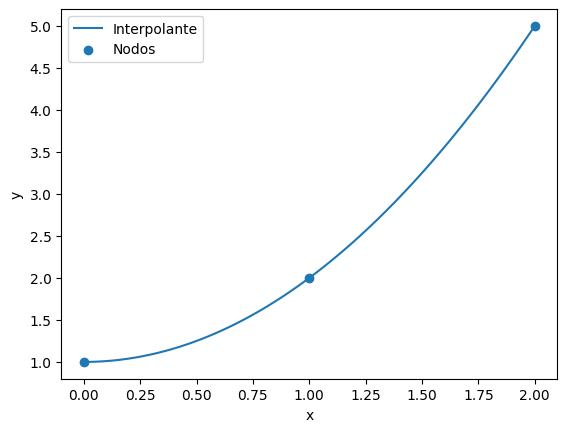

In [4]:
z = np.linspace(x.min(),x.max(),100)
plt.plot(z,lagrange(z,x,y),label='Interpolante')
plt.scatter(x,y,label='Nodos')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

## 4. Si necesitas coeficientes
La evaluación de Lagrange no devuelve automáticamente coeficientes en potencias de x. Usa el notebook de Vandermonde con base monomial si el problema pide esos coeficientes. Como comprobación independiente, `np.polyfit(x,y,len(x)-1)` usa orden descendente y `np.polyval` lo evalúa (no lo uses en lugar del método pedido).

In [5]:
coef = np.polyfit(x,y,len(x)-1)
print('Coeficientes descendentes:',coef)
assert np.allclose(np.polyval(coef,z),lagrange(z,x,y))

Coeficientes descendentes: [1.00000000e+00 4.96506831e-16 1.00000000e+00]


**Cuidado:** interpolar no es ajustar por mínimos cuadrados. Coincidir en los nodos no garantiza precisión entre ellos. Muchos nodos equiespaciados pueden causar oscilaciones y errores numéricos; extrapolar fuera del intervalo es arriesgado.